<h3><center>Introduction to Building a Quant Pricing Library</center></h3>
<h1><center>Volatility Surface, Numerical Greeks</center></h1>
<h3><center>Tamas Glatz</h3>
<h3><center>(Based on Gabor Friedmann's Lecutre Notes)</center></h3>
<h4><center>14 October, 2026</center></h4>


### <b> The law of supply and demand:</b>
* Number of people who buy go $ \uparrow $, or sell go $ \downarrow $ $\Longrightarrow $ Price goes $\uparrow$
* Number of people who buy go $ \downarrow $, or sell go $ \uparrow $ $\Longrightarrow $ Price goes $\downarrow $
* This simple dynamic drives the price of many goods... For example
    * Market price of face masks during covid
    * <b> Market price of options<b> (quotes)

## <b>Goal of option pricing:</b>
* Come up with a model that is able to re-price "frequently traded" (liquid) products
* Use the model to understand how to eliminate risks (hedging)
* Use the model to price other, "non-frequently traded" (illiquid) products

# Moneyness

Measures whether the option would make money if it were exercised immediately. We define moneyness as current spot price divided by strike price:
$$ M = \dfrac{S_t}{K} $$

At $M = 1$, the option is called at-the-money (ATM). Otherwise, the option is called either in-the-money (ITM) or out-of-the-money (OTM).

<img src="./img/moneyness.jpg" style="margin-left:auto; margin-right:auto; width: 1000px;" />

## What did we learn?

Black-Scholes model assumptions:
* Underlying asset price follows GBM:

$$ dS_{t}=\mu S_{t}\,dt+\sigma S_{t}\,dW_{t} $$
* Underlying asset price has <b>known and constant</b> volatility ($\sigma$)
* Log returns of the underlying asset are normally distributed

### Under these assumptions we can derive the price of a European Call option $c_0$ (by ruling out arbitrage):

$$
c_0 = S_0 N(d_1) - K e^{-rT} N(d_2)
$$
where
$$
d_1 = \frac{\ln\left(\frac{S_0}{K}\right) + \left(r + \frac{\sigma^2}{2}\right)T}{\sigma\sqrt{T}}; \, d_2 = d_1 - \sigma\sqrt{T}
$$
So essentially $c_0$ is a function of 5 parameters:
$$
c_0 = f_{BS}\left(S_0, K, T, r, {\sigma}\right)
$$
#### Which of these parameters are known to us?

#### Remember, our goal with the model is NOT to determine how much the option we observe should cost, but to know how to hedge it.

$$ \color{red}{\sigma} = f^{-1}_{BS}\left(S_0, K, T, r, c_0\right) $$

<b>Implied volatility</b>: The volatility obtained from market quotes using Black-Scholes formula. It represents what the market is implying the volatility will be in the future based on option prices.

#### Based on BS assumptions, implied volatility should be constant for all options on a given underlying. Is that true?

<img src="./img/implied_vol_smile.jpg" style="margin-left:auto; margin-right:auto; width: 1500px;" />

<img src="./img/smile_skew.jpg" style="margin-left:auto; margin-right:auto; width: 1500px;" alt="Source: https://analystprep.com/study-notes/frm/part-2/market-risk-measurement-and-management/volatility-smiles/" />

## Why?

Highligting just one concept: Protective Put Option Strategy

There is high demand for put options with low strike as they serve as a protection against huge losses.

<img src="./img/protective_put.jpg" style="margin-left:auto; margin-right:auto; width: 400px;" />


<img src="./img/implied_vol_termskew.jpg" style="margin-left:auto; margin-right:auto; width: 1500px;" />

<b>Conclusion</b>: The volatility in our model should depend on strike and expiry: <b>$ \sigma = \sigma(K,T) $<b>

Using market quotes, we can derive an <b>implied volatility grid</b>. Applying some interpolation technique between grid points we can build an <b>implied volatility surface</b>.

Let's look at some examples!

BlueChip Bank, TipTop Solutions, Money Mall


In [2]:
# Add current folder and QuantCourseBP folder to syspath to import modules
import sys
import numpy as np
from pathlib import Path
current = Path(Path().resolve())
sys.path.append(str(current))
sys.path.append(str(current.parents[2]))

from src.utils import *
from src.market_data import *

# Make charts interactive - remove this line if charts throws error
%matplotlib widget

# Initialize market data
MarketData.initialize()

In [3]:
underlying = Stock.BLUECHIP_BANK
volgrid = MarketData.get_volgrid()[underlying]

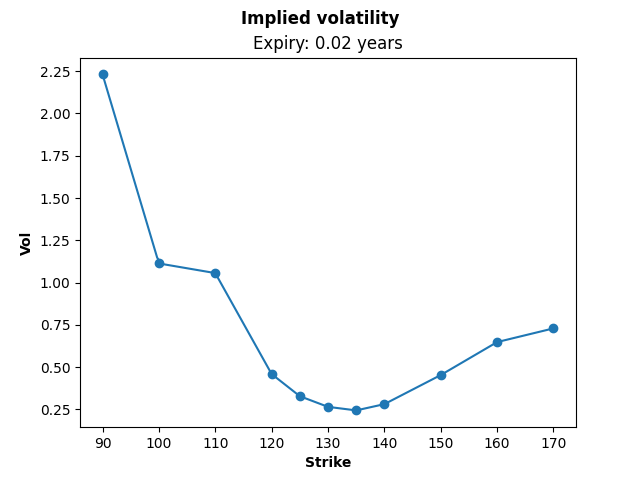

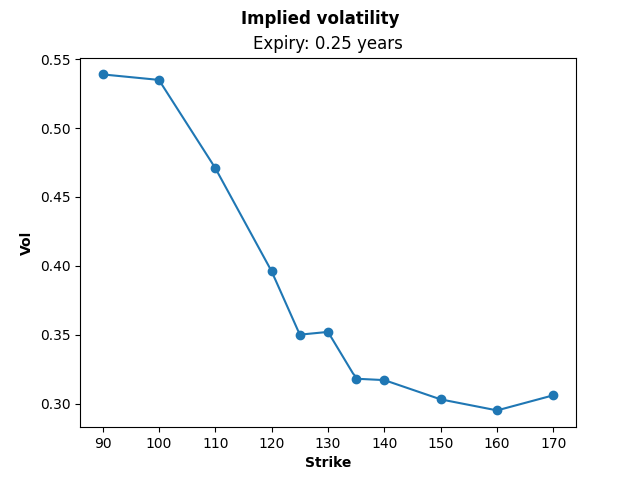

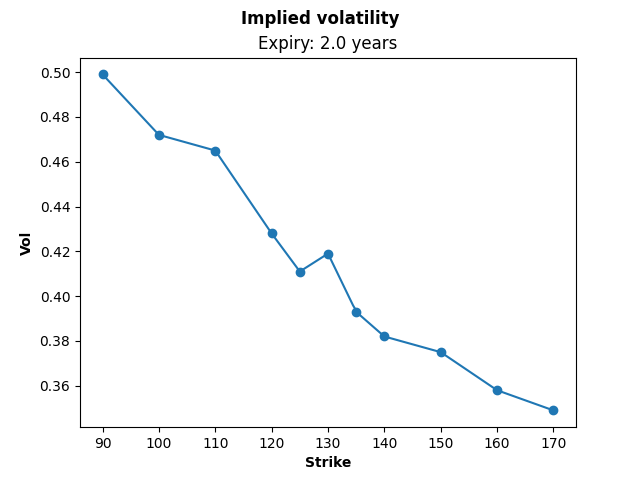

In [4]:
flag = True
plot_vol_slice(volgrid, expiry=0.02, linear_interpolation=flag) # 7D
plot_vol_slice(volgrid, expiry=0.25, linear_interpolation=flag) # 3M
plot_vol_slice(volgrid, expiry=2.00, linear_interpolation=flag) # 2Y

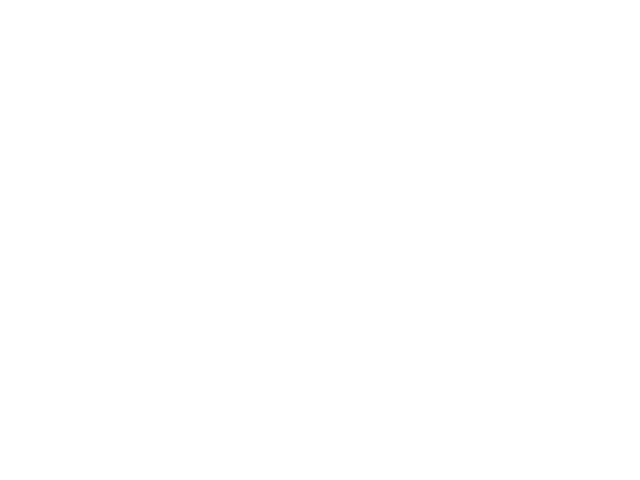

In [5]:
plot_vol_surface(volgrid)

## What changes?

Underlying asset price diffusion:
$$ \; dS_{t}=\mu S_{t}\,dt+\sigma S_{t}\,dW_{t} $$


$$ \; dS_{t}=\mu S_{t}\,dt+\color{red}{\sigma(K,T)} S_{t}\,dW_{t} $$

We can determine $ \sigma(K,T) $ based on the contract we want to price, then use that constant within the Black-Scholes framework. Let's call this extension of BS model as <b>flat volatility model</b>.

Volatility market data is no longer a single number, but a tabular data (grid) for each underlying, hence we outsource them to csv files for maintainability.

<br>
<br>

Let's do coding!

# Greeks

* Understanding the sensitivities of a porfolio is crutial to eliminate them (hedging)
* So far we had analytical formulas to calculate greeks, usually this is not the case
* In most cases we calculate greeks numerically using finite difference approximation (forward, backward, central)

## Finite difference approximation (central, absolute)
$$ f'(x)\approx\dfrac{f(x+\Delta)-f(x-\Delta)}{2\Delta} $$

$$ f''(x)\approx\dfrac{f'(x+\dfrac{\Delta}{2})-f'(x-\dfrac{\Delta}{2})}{\Delta}\approx\dfrac{f(x+\Delta)-2f(x)+f(x-\Delta)}{\Delta^2} $$

# Tasks

## Pricer - pricer.py

* Implement calc_delta() function using finite difference approximation.
* Compare the results of analytic and numerical formulas for delta and gamma.

# Assignments - Numerical greeks

1. Introduce two class variables in Pricer that store the finite difference method (forward, backward, central) to be used in numerical greek calculation, and whether the bump size is absolute or relative.
2. Create two Enums to store the labels.
3. Implement all combinations for delta and gamma calculation.<br>
4. Compare greeks using the analytic and the finite difference approximation on a set of European options and visualize the numerical error.
5. Compare absolute and relative bumping and suggest optimal bump sizes. **(15 points)**

# Tasks

## MarketData - market_data.py

* Understand the new structure of MarketData class
* Understand how VolGrid class works

## MarketModel - model.py

* Implement BSVol and FlatVol models in the pricing library

## Jupyter notebook

* Price a few contracts using both Black-Scholes and FlatVol models

In [1]:
# Add current folder and QuantCourseBP folder to syspath to import modules
import sys
from pathlib import Path
current = Path(Path().resolve())
sys.path.append(str(current))

for p in [str(current.parents[2]),str(current.parents[2]/"src") ]:
    if p in sys.path:
        sys.path.remove(p)

from market_data import MarketData
from pricer import *
from model import *

In [2]:
# Added: initialize the local MarketData (the earlier cell only initializes src.MarketData)
#AI was used to locate the mkt folder and to identify a missing MarketData.initialize() call in the lecture notebook.

MarketData.initialize()
print(MarketData.market_folder.resolve())
print(sys.executable)

/Users/carlos/proyectos/QuantCourseBP/mkt
/Users/carlos/proyectos/QuantCourseBP/venv_quant_course_v312/bin/python3.12


In [3]:
und = Stock.BLUECHIP_BANK
put_call = PutCallFwd.CALL
ls = LongShort.LONG
strike = 1.0 * MarketData.get_spot()[und] # at-the-money strike i.e. strike = spot price
strike_itm = strike * 1.1
exp = 1

forward = ForwardContract(und, ls, strike, exp)
option = EuropeanContract(und, put_call, ls, strike , exp)
option_itm = EuropeanContract(und, put_call, ls, strike_itm, exp)

print(option)

{'underlying': <Stock.BLUECHIP_BANK: 'BLUECHIP_BANK'>, 'type': <PutCallFwd.CALL: 'CALL'>, 'long_short': <LongShort.LONG: 'LONG'>, 'strike': np.float64(130.17), 'expiry': 1}


In [4]:
## Added: Reproducing the lecture results before any modification

# We use these figures as a reference. We run this cell again after every change (Enums, class variables, new `calc_delta` and `calc_gamma`). 
# The results should be the same with the default parameters (central difference, relative bump of 1%); if they vary, 
# the modification has broken the library.

# Expected Results 

# price 22.515663, 
# delta analytic 0.626163 
# delta bump 0.626132 
# gamma 0.007642.

# Parameters: K = S = 130.17, T = 1

model_test = FlatVolModel(und)                                       # model reads the inputs:  rate, spot and vol grid of BLUECHIP_BANK
pricer_test = EuropeanAnalyticPricer(option, model_test, Params())   # pricer reads the inputs:  contract + model + parameters

print("vol            ", f"{model_test.get_vol(option.strike, option.expiry):.6f}")  # sigma(K, T) from the grid
print("price          ", f"{pricer_test.calc_fair_value():.6f}")
print("delta analytic ", f"{pricer_test.calc_delta(GreekMethod.ANALYTIC):.6f}")
print("delta bump     ", f"{pricer_test.calc_delta(GreekMethod.BUMP):.6f}")
print("gamma bump     ", f"{pricer_test.calc_gamma(GreekMethod.BUMP):.6f}")
print("gamma analytic ", f"{pricer_test.calc_gamma(GreekMethod.ANALYTIC):.6f}")

vol             0.380830
price           22.515663
delta analytic  0.626163
delta bump      0.626132
gamma bump      0.007642
gamma analytic  0.007642


In [5]:
# Added: checking that the new Enums are defined correctly

# Part (a): two new Enums in enums.py, following the pattern of GreekMethod(str, Enum):
#   BumpType: ABSOLUTE, RELATIVE           -> whether the bump size is absolute or relative
#   FDMethod: FORWARD, BACKWARD, CENTRAL   -> finite difference method used for numerical Greeks


print(list(BumpType))                  # 1) all members of BumpType
print(BumpType.RELATIVE == 'RELATIVE') # 2) a member compared with its string

print(list(FDMethod))                  # 1) all members of FDMethod
print(FDMethod.CENTRAL == 'CENTRAL')   # 2) a member compared with its string


[<BumpType.ABSOLUTE: 'ABSOLUTE'>, <BumpType.RELATIVE: 'RELATIVE'>]
True
[<FDMethod.FORWARD: 'FORWARD'>, <FDMethod.BACKWARD: 'BACKWARD'>, <FDMethod.CENTRAL: 'CENTRAL'>]
True


In [6]:
# Added: checking the new class variables of Pricer
# Part (b): new class variables in Pricer (see pricer.py, NEW 1).

print(Pricer.finite_difference_method)       # read from the class
print(Pricer.bump_convention)
print(Pricer.absolute_bump_size)
print(pricer_test.finite_difference_method)  # read from an object: same value as the class

FDMethod.CENTRAL
BumpType.RELATIVE
0.01
FDMethod.CENTRAL


In [7]:
# Added: checking calc_bump_size
# Part (c): calc_bump_size in Pricer (see pricer.py, NEW 2).

print(f"{pricer_test.calc_bump_size():.6f}")   # RELATIVE (default): 0.01 * 130.17

Pricer.bump_convention = BumpType.ABSOLUTE
print(pricer_test.calc_bump_size())            # ABSOLUTE: absolute_bump_size

Pricer.bump_convention = 'OTHER'               # an invalid label
try:
    pricer_test.calc_bump_size()
except ValueError as error:
    print("ValueError:", error)

Pricer.bump_convention = BumpType.RELATIVE     # restore the default

1.301700
0.01
ValueError: Unsupported bump convention


In [8]:
# Added: Testing all combinations of finite difference methods and bump conventions

# Part (c): calc_delta and calc_gamma in Pricer (see pricer.py, NEW 3).
# The combinations are based on the lecture's bump-and-revalue approach.
# AI suggested organising the tests by bump convention and finite difference method.

# Calculate analytical Delta and Gamma
print("ANALYTIC")
print("Delta:", f"{pricer_test.calc_delta(GreekMethod.ANALYTIC):.6f}")
print("Gamma:", f"{pricer_test.calc_gamma(GreekMethod.ANALYTIC):.6f}")

# Test relative and absolute bump conventions
for convention, size in [(BumpType.RELATIVE, 0.01), (BumpType.ABSOLUTE, 1.3017)]:

    Pricer.bump_convention = convention
    Pricer.absolute_bump_size = size

    print(f"\n{convention.value} (h = {pricer_test.calc_bump_size():.4f})")

    # Test FORWARD, BACKWARD and CENTRAL methods
    for fd_method in FDMethod:

        Pricer.finite_difference_method = fd_method
        delta = pricer_test.calc_delta(GreekMethod.BUMP)
        gamma = pricer_test.calc_gamma(GreekMethod.BUMP)
        print(f"{fd_method.value}: Delta = {delta:.6f}, Gamma = {gamma:.6f}")


# Restore default settings
Pricer.bump_convention = BumpType.RELATIVE
Pricer.finite_difference_method = FDMethod.CENTRAL
Pricer.absolute_bump_size = 0.01

ANALYTIC
Delta: 0.626163
Gamma: 0.007642

RELATIVE (h = 1.3017)
FORWARD: Delta = 0.631106, Gamma = 0.007500
BACKWARD: Delta = 0.621159, Gamma = 0.007782
CENTRAL: Delta = 0.626132, Gamma = 0.007642

ABSOLUTE (h = 1.3017)
FORWARD: Delta = 0.631106, Gamma = 0.007500
BACKWARD: Delta = 0.621159, Gamma = 0.007782
CENTRAL: Delta = 0.626132, Gamma = 0.007642


In [9]:
# Part (d), d1: a set of European options

# Task: Compare greeks using the analytic and the finite difference approximation
# on a set of European options and visualize the numerical error
# Set: strikes around the spot (0.8S to 1.2S), two expiries (0.5 and 1), calls and puts -> 20 options.
# AI note: the choice of the option set was suggested by AI; the code is my own.

# Creating a set of European options

# Define the underlying asset
und = Stock.BLUECHIP_BANK

# Get the spot price
S = MarketData.get_spot()[und]

# Define strikes, expirations and option types
strikes = [0.8*S, 0.9*S, S, 1.1*S, 1.2*S]
expirations = [0.5, 1.0]
put_calls = [PutCallFwd.CALL, PutCallFwd.PUT]

# Create an empty list to store the options
options = []

# We are using the first for loop to iterate over all strike prices
for K in strikes:

    # We are using the second for loop to iterate over all expiration dates
    for T in expirations:

        # We are using the third for loop to iterate over calls and puts
        for pc in put_calls:

            # We are creating a European option for each combination
            contract = EuropeanContract(und, pc, ls, K, T)
            # We are adding the option to the list
            options.append(contract)

# Print the total number of options
print("Number of European options:", len(options))

Number of European options: 20


We first create a grid of relative bump sizes, ranging from $10^{-1}$ to $10^{-8}$. We use 29 equally spaced exponents, which gives four intervals per decade.

The purpose is to examine how the numerical error changes as the bump size decreases. In particular, we want to observe the balance between truncation error and round-off error and identify a suitable bump size for the numerical approximation.

In [10]:
###  Numerical error as a function of the bump size

# We follow the structure of the lecture code (bump-and-revalue loop of Pricer, Lecture 6)
# The skeleton was proposed by AI and completed by me.

# d2a: grid of relative bump sizes (epsilon), from 1e-1 to 1e-8.
# We use four intervals per decade.

exponents = np.linspace(-1, -8, 29)

# We are using powers of 10 to obtain the relative bump sizes
eps_grid = 10.0 ** exponents

print(len(eps_grid), eps_grid[0], eps_grid[4], eps_grid[-1])

29 0.1 0.01 1e-08


In this part, we calculate the absolute errors for Delta and Gamma.

First, we calculate the exact values using the analytical method. Then, we calculate the numerical values using different finite difference methods and bump sizes.

Finally, we compare both results and store the absolute errors in a dictionary for later analysis.

In [11]:
# d2b: calculate the absolute numerical errors for delta and gamma
# This cell only defines the function; it is tested in the next cell with the lecture's ATM call.

def calculate_errors(contract):

    # We are using the relative bump convention, because we vary the relative bump size   # added
    Pricer.bump_convention = BumpType.RELATIVE                                             # added

    # We are creating the model of the contract's underlying asset
    model_d = FlatVolModel(contract.underlying)

    # We are creating the analytic pricer
    pricer_d = EuropeanAnalyticPricer(contract, model_d, Params())

    # We are calculating the analytical Delta and Gamma
    # These values will be used as reference values
    delta_exact = pricer_d.calc_delta(GreekMethod.ANALYTIC)
    gamma_exact = pricer_d.calc_gamma(GreekMethod.ANALYTIC)

    # We are creating an empty dictionary to store the errors
    errors = {}

    # We are using a for loop to iterate over the three finite difference methods
    for fd_method in FDMethod:

        # We are selecting the current finite difference method
        Pricer.finite_difference_method = fd_method

        # We are creating empty lists to store the errors
        delta_errors = []
        gamma_errors = []

        # We are using a for loop to iterate over all bump sizes
        for eps in eps_grid:

            # We are setting the relative bump size
            Pricer.relative_bump_size = eps

            # We are calculating the numerical Delta and its absolute error
            delta_bump = pricer_d.calc_delta(GreekMethod.BUMP)
            delta_errors.append(abs(delta_bump - delta_exact))

            # We are calculating the numerical Gamma and its absolute error
            gamma_bump = pricer_d.calc_gamma(GreekMethod.BUMP)
            gamma_errors.append(abs(gamma_bump - gamma_exact))

        # We are storing the errors for the current finite difference method
        errors[fd_method] = {
            "delta": delta_errors,
            "gamma": gamma_errors
        }

    # We are restoring the default finite difference method
    Pricer.finite_difference_method = FDMethod.CENTRAL

    # We are restoring the default relative bump size
    Pricer.relative_bump_size = 0.01

    # We are restoring the default bump convention
    Pricer.bump_convention = BumpType.RELATIVE

    return errors

We now check the results using the ATM call from the lecture. We use a relative bump size of $\varepsilon = 0.01$ and print the absolute errors for Delta and Gamma for each finite difference method.
This allows us to verify that the function gives the same errors as in part (c) (and, for the central method, as in the lecture).

In [12]:
# Added: check of d2 with the lecture's ATM call at epsilon = 0.01 (position 4 of the grid)
errors_atm = calculate_errors(option)
i = 4
print(f"eps = {eps_grid[i]:.4f}")
for fd_method in FDMethod:
    print(f"{fd_method.value:<9} delta error {errors_atm[fd_method]['delta'][i]:.6e}"
          f"   gamma error {errors_atm[fd_method]['gamma'][i]:.6e}")

eps = 0.0100
FORWARD   delta error 4.943000e-03   gamma error 1.416336e-04
BACKWARD  delta error 5.004162e-03   gamma error 1.401624e-04
CENTRAL   delta error 3.058064e-05   gamma error 1.049390e-07




In this part, we plot the absolute errors for Delta and Gamma using logarithmic scales on both axes.

We create two plots, one for each Greek, and show the results for all finite difference methods.

These plots help us see how the numerical errors change with the bump size and compare the different methods.

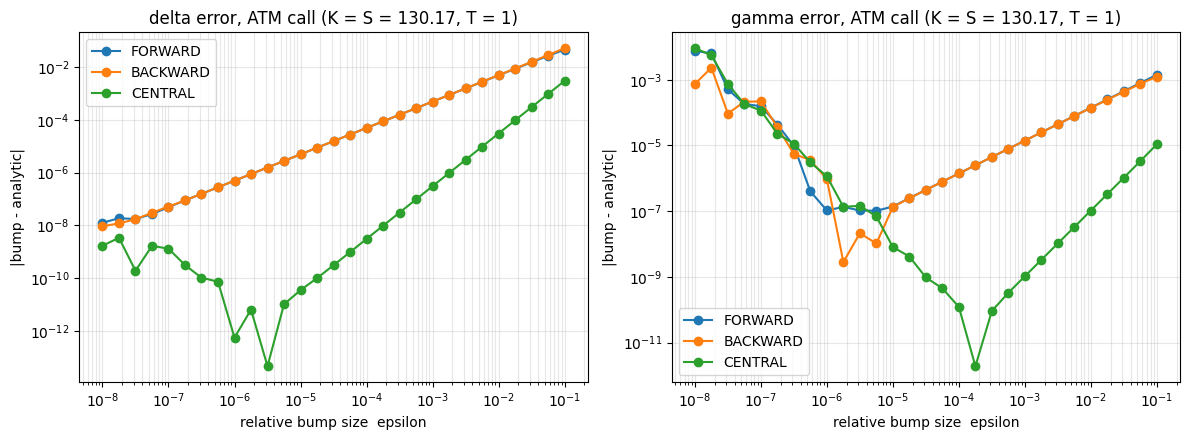

In [13]:
# d3: log-log plots of the absolute error for the lecture's ATM call
import matplotlib.pyplot as plt

# We are creating two plots side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# We are iterating over Delta and Gamma
for ax, greek in [(axes[0], "delta"), (axes[1], "gamma")]:

    # We are plotting one curve for each finite difference method
    for fd_method in FDMethod:

        ax.plot(eps_grid, errors_atm[fd_method][greek],
                "o-", label=fd_method.value)

    # We are setting logarithmic scales on both axes
    ax.set_xscale("log")
    ax.set_yscale("log")

    # We are adding labels and a title
    ax.set_xlabel("relative bump size  epsilon")
    ax.set_ylabel("|bump - analytic|")
    ax.set_title(f"{greek} error, ATM call (K = S = 130.17, T = 1)")

    # We are displaying the legend and grid
    ax.legend()
    ax.grid(True, which="both", alpha=0.3)

# We are adjusting the spacing between the plots
plt.tight_layout()

# We are displaying the figures
plt.show()

### d3: Numerical error analysis and conclusions

### 1. Slopes on the right-hand side

On the right-hand side of the plots, the FORWARD and BACKWARD methods increase approximately one decade in error for every decade increase in $\varepsilon$. This indicates a first-order truncation error:

$$
E(\varepsilon)=O(\varepsilon).
$$

The CENTRAL method increases approximately two decades in error for every decade increase in $\varepsilon$. This indicates a second-order truncation error:

$$
E(\varepsilon)=O(\varepsilon^2).
$$

Therefore, the CENTRAL method is generally more accurate when truncation error dominates.

### 2. Delta panel: FORWARD and BACKWARD

The FORWARD and BACKWARD curves are almost on top of each other because their absolute errors are very similar.

In part (c), their signed errors were approximately $+0.0049$ and $-0.0050$, respectively. Although the signs are opposite, their absolute values are almost equal. Since the graph shows absolute errors, the two curves overlap.

### 3. Very small epsilon

When $\varepsilon$ becomes very small, the error stops decreasing and may increase or fluctuate.

This happens because round-off errors and numerical cancellation become more important. These effects can produce irregular peaks and changes in the error.

### 4. Location of the minimum errors

The minimum of the CENTRAL Delta curve is approximately between:

$$
\varepsilon=10^{-6}
\quad \text{and} \quad
3\times10^{-6}.
$$

The minimum of the CENTRAL Gamma curve is approximately at:

$$
 \varepsilon= 2 \times 10^{-4}.
$$

The Gamma calculation is more sensitive to small bump sizes because the central difference formula divides by $h^2$, while the Delta formula divides by $h$. Therefore, round-off errors can have a stronger effect on Gamma.

### 5. Comparison with the lecture's bump size

The lecture uses:

$$
\varepsilon=0.01.
$$

The minimum error of the CENTRAL method is considerably smaller than the error obtained with this bump size.

We can measure the improvement by comparing the error at $\varepsilon=0.01$ with the minimum error:
$$
\log_{10}\left(
\frac{E(0.01)}{E(\varepsilon_{\min})}
\right).
$$

For CENTRAL Delta, this corresponds to approximately 8 orders of magnitude.

This shows that choosing an appropriate bump size can significantly improve the accuracy of numerical Greeks.

### d4: Numerical error on the whole set of 20 European options
### d4: Errors for the whole set of options

In this part, we repeat the error study of d2 for every option of the set created in d1. We use a for loop over the 20 options, and for each option we calculate the Delta and Gamma errors with the function `calculate_errors`. The results are stored in the list `all_errors`, in the same order as the list `options`.

In [14]:
# d4a: errors of every option of the set


all_errors = []
for contract in options:

    all_errors.append(calculate_errors(contract))

print("Options analysed:", len(all_errors))

Options analysed: 20


We now plot the error of the central method for the 20 options, with one line per option. As in d3, we use logarithmic axes. In this way, we can see whether the shape of the error curve and the location of the minimum change with the option (strike, expiry, call or put).

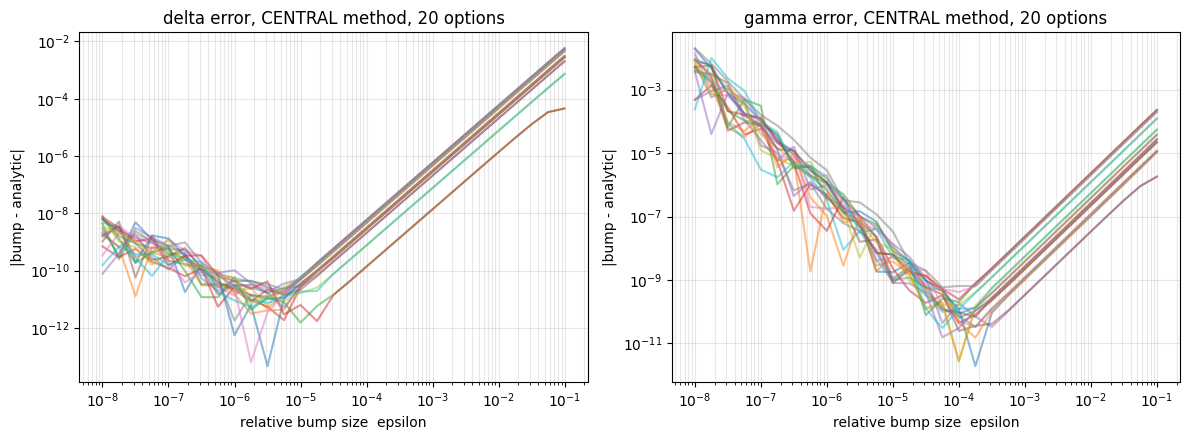

In [15]:
# d4b: central-difference error of every option (one line per option)

# We are creating two plots side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, greek in [(axes[0], "delta"), (axes[1], "gamma")]:

    for errors in all_errors:
        ax.plot(eps_grid, errors[FDMethod.CENTRAL][greek],
                "-", alpha=0.5)
        
    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_xlabel("relative bump size  epsilon")
    ax.set_ylabel("|bump - analytic|")
    ax.set_title(f"{greek} error, CENTRAL method, 20 options")

    ax.grid(True, which="both", alpha=0.3)

plt.tight_layout()

# We are displaying the figures
plt.show()

In this part, we find the best bump size for Delta and Gamma for each option.

We use the CENTRAL method and search for the bump size that gives the smallest numerical error. We also compare this minimum error with the error obtained using the lecture's bump size of $\varepsilon = 0.01$.

Finally, we print the results for all options.

In [16]:
# d4c: for each option, the epsilon of the smallest central error and the error at epsilon = 0.01

for k in range(len(options)):

    contract = options[k]
    line = f"{k:2d} {contract.derivative_type.value:<4} K/S = {contract.strike / S:.1f}  T = {contract.expiry}"

    # We are iterating over Delta and Gamma
    for greek in ["delta", "gamma"]:
        
        errs = all_errors[k][FDMethod.CENTRAL][greek]   # We are retrieving the central-difference errors
        eps_min = eps_grid[errs.index(min(errs))]     # We are finding the epsilon corresponding to the minimum error
        line += f" | {greek}: best eps {eps_min:.0e}, error at 0.01 {errs[4]:.1e}"  

    print(line)

 0 CALL K/S = 0.8  T = 0.5 | delta: best eps 6e-06, error at 0.01 4.6e-05 | gamma: best eps 1e-04, error at 0.01 3.9e-07
 1 PUT  K/S = 0.8  T = 0.5 | delta: best eps 3e-06, error at 0.01 4.6e-05 | gamma: best eps 1e-04, error at 0.01 3.9e-07
 2 CALL K/S = 0.8  T = 1.0 | delta: best eps 3e-06, error at 0.01 2.8e-05 | gamma: best eps 1e-04, error at 0.01 2.2e-07
 3 PUT  K/S = 0.8  T = 1.0 | delta: best eps 6e-06, error at 0.01 2.8e-05 | gamma: best eps 1e-04, error at 0.01 2.2e-07
 4 CALL K/S = 0.9  T = 0.5 | delta: best eps 3e-06, error at 0.01 5.9e-05 | gamma: best eps 3e-04, error at 0.01 3.4e-08
 5 PUT  K/S = 0.9  T = 0.5 | delta: best eps 3e-06, error at 0.01 5.9e-05 | gamma: best eps 1e-04, error at 0.01 3.4e-08
 6 CALL K/S = 0.9  T = 1.0 | delta: best eps 1e-06, error at 0.01 3.1e-05 | gamma: best eps 2e-04, error at 0.01 1.2e-07
 7 PUT  K/S = 0.9  T = 1.0 | delta: best eps 1e-06, error at 0.01 3.1e-05 | gamma: best eps 2e-04, error at 0.01 1.2e-07
 8 CALL K/S = 1.0  T = 0.5 | del

### d4: Conclusions

1. CENTRAL is the most accurate method. By Taylor's theorem (Lecture 7), its truncation error is $O(\varepsilon^2)$, while FORWARD and BACKWARD have $O(\varepsilon)$.
2. The best relative bump size is approximately $10^{-6}$ to $2\times10^{-5}$ for Delta, and $3\times10^{-5}$ to $3\times10^{-4}$ for Gamma.
3. For very small $\varepsilon$, round-off errors dominate, because the formulas divide by $h$ (Delta) or $h^2$ (Gamma). For this reason, Gamma needs a larger bump size than Delta.
4. A call and a put with the same strike and expiry have almost the same errors, as expected from put-call parity.
5. The lecture's bump size $\varepsilon = 0.01$ is not optimal: smaller bump sizes give more accurate results, especially for Delta.

## Part (e): Absolute and relative bumping

In this part, we compare absolute and relative bumping and suggest optimal bump sizes. With relative bumping, the bump size is $h = \varepsilon S$, so it changes with the spot. With absolute bumping, $h$ is the same for every stock. To see the difference, we use stocks with different spot prices.

We follow the code of part (d): the contracts are created as in d1 and in the lecture notebook (Lecture 6: `MarketData.get_spot()` and `EuropeanContract`), and the errors are calculated with the same structure as in d2. The idea was proposed by AI.

**e1:** we create one ATM call ($K = S$, $T = 1$) on each of the four stocks, and we print the spot of each stock.

In [17]:
# e1: one ATM call (T = 1) on each stock
stocks = [
    Stock.TEST_COMPANY,
    Stock.BLUECHIP_BANK,
    Stock.TIPTOP_SOLUTIONS,
    Stock.MONEY_MALL
]

atm_calls = []

for stock in stocks:

    # We are getting the spot price of the current stock
    spot = MarketData.get_spot()[stock]

    # We are creating an ATM call contract
    atm_calls.append(
        EuropeanContract(stock, PutCallFwd.CALL, LongShort.LONG, spot, 1.0)
    )

    print(stock.value, spot)

TEST_COMPANY 100.0
BLUECHIP_BANK 130.17
TIPTOP_SOLUTIONS 177.32
MONEY_MALL 250.86


In [18]:
# e2: grid of absolute bump sizes h
h_exponents = np.linspace(1, -7, 33)
h_grid = 10.0 ** h_exponents

print(len(h_grid), h_grid[0], h_grid[4], h_grid[-1])

33 10.0 1.0 1e-07


**e3:** With absolute bumping, $h$ is the same for every stock, so it does not adapt to the spot. We expect the best $h$ to depend on the spot.

To check this, we repeat the study of d2 with absolute bumping on the four ATM calls of e1. The function `calculate_errors_absolute` is the same as `calculate_errors`, but it uses the ABSOLUTE convention and the grid `h_grid`.

In [19]:
def calculate_errors_absolute(contract):

    # We are selecting the ABSOLUTE bump convention
    Pricer.bump_convention = BumpType.ABSOLUTE

    # We are creating the model and analytic pricer
    model_d = FlatVolModel(contract.underlying)
    pricer_d = EuropeanAnalyticPricer(contract, model_d, Params())

    # We are calculating the analytical Delta and Gamma
    delta_exact = pricer_d.calc_delta(GreekMethod.ANALYTIC)
    gamma_exact = pricer_d.calc_gamma(GreekMethod.ANALYTIC)

    errors = {}

    # We are iterating over the finite difference methods
    for fd_method in FDMethod:

        Pricer.finite_difference_method = fd_method

        delta_errors = []
        gamma_errors = []

        # We are iterating over all absolute bump sizes
        for h in h_grid:

            Pricer.absolute_bump_size = h

            delta_bump = pricer_d.calc_delta(GreekMethod.BUMP)
            gamma_bump = pricer_d.calc_gamma(GreekMethod.BUMP)

            delta_errors.append(abs(delta_bump - delta_exact))
            gamma_errors.append(abs(gamma_bump - gamma_exact))

        errors[fd_method] = {
            "delta": delta_errors,
            "gamma": gamma_errors
        }

    # We are restoring the default settings
    Pricer.finite_difference_method = FDMethod.CENTRAL
    Pricer.bump_convention = BumpType.RELATIVE
    Pricer.relative_bump_size = 0.01
    Pricer.absolute_bump_size = 0.01

    return errors


# We are calculating and printing the results for all four options
absolute_errors = []

for i, contract in enumerate(atm_calls):

    result = calculate_errors_absolute(contract)
    absolute_errors.append(result)

    print(f"\nOption {i + 1}: {contract.underlying}")
    print(f"Spot: {contract.strike}")

    print("Central Delta errors:")
    print(result[FDMethod.CENTRAL]["delta"])

    print("Central Gamma errors:")
    print(result[FDMethod.CENTRAL]["gamma"])

print("\nOptions analysed:", len(absolute_errors))


Option 1: Stock.TEST_COMPANY
Spot: 100.0
Central Delta errors:
[np.float64(0.004252927768311654), np.float64(0.0013621867152623368), np.float64(0.00043249840748482704), np.float64(0.00013694196252922453), np.float64(4.332225423064884e-05), np.float64(1.3701440253921504e-05), np.float64(4.33294987822741e-06), np.float64(1.3702164164408615e-06), np.float64(4.3330225318882754e-07), np.float64(1.370222914021113e-07), np.float64(4.333044334448033e-08), np.float64(1.3702406542748236e-08), np.float64(4.332291414499423e-09), np.float64(1.3714813729137632e-09), np.float64(4.3300174557003857e-10), np.float64(1.3988532554520816e-10), np.float64(3.8836933669017526e-11), np.float64(1.1683987111155147e-12), np.float64(8.3313356213921e-12), np.float64(1.0025869023877476e-11), np.float64(1.396793791741402e-11), np.float64(3.042022189703175e-11), np.float64(8.3313356213921e-12), np.float64(4.99826846578344e-11), np.float64(4.478848403266511e-10), np.float64(1.420317974343277e-09), np.float64(1.4521754

We check that `calculate_errors_absolute` works correctly. For TEST_COMPANY ($S = 100$), $h = 1$ is the same bump as $\varepsilon = 0.01$, so both functions must give the same error.

In [20]:
# Added: check of e3 — for TEST_COMPANY (S = 100), h = 1 is exactly 1% of the spot
err_rel = calculate_errors(atm_calls[0])
print(f"{absolute_errors[0][FDMethod.CENTRAL]['delta'][4]:.6e}  {err_rel[FDMethod.CENTRAL]['delta'][4]:.6e}")

4.332225e-05  4.332225e-05


**e4:** We calculate the errors of the same four ATM calls with relative bumping, using `calculate_errors` of d2. In e5, we compare these errors with the absolute bumping errors of e3.

In [21]:
# e4: relative bump errors for the four ATM calls
relative_errors = []

for contract in atm_calls:
    relative_errors.append(calculate_errors(contract))

print("Options analysed:", len(relative_errors))

Options analysed: 4


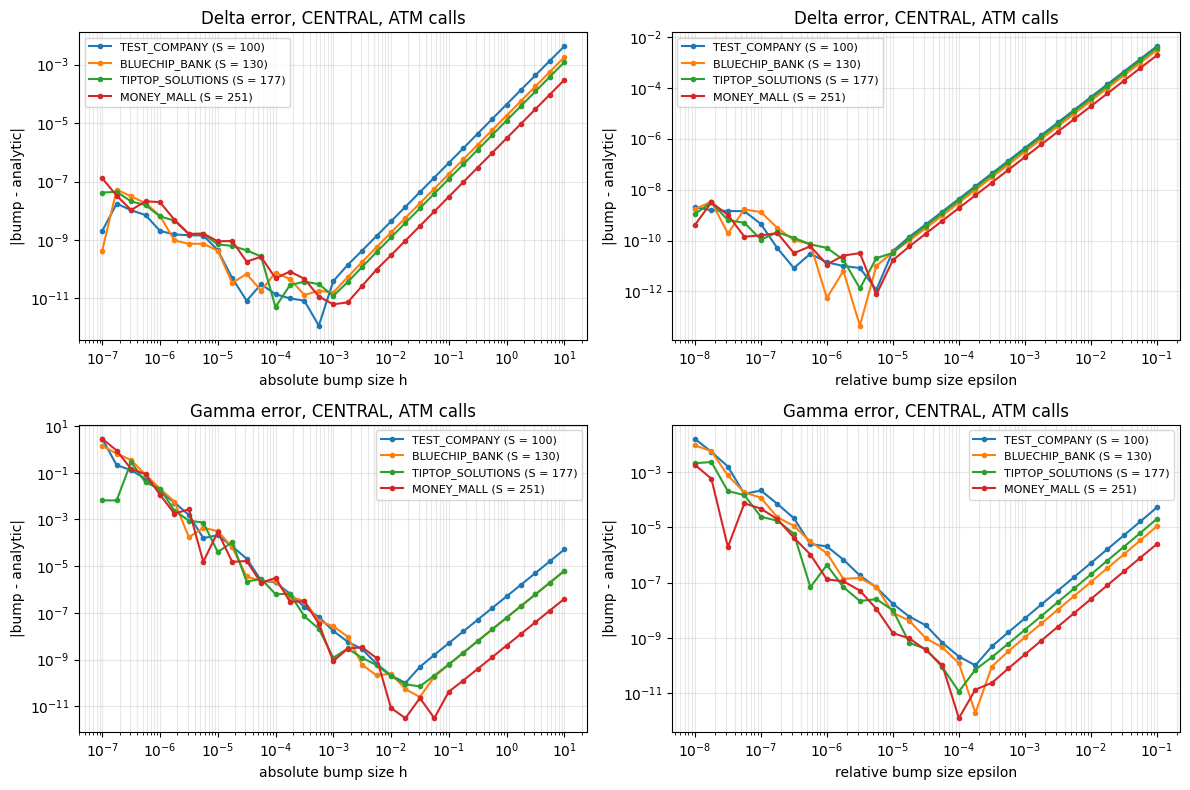

In [22]:
# e5: central-difference error
# Left column: absolute bump h
# Right column: relative bump epsilon

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for row, greek in [(0, "delta"), (1, "gamma")]:

    for k in range(len(stocks)):

        # We are creating a label for each stock
        label = f"{stocks[k].value} (S = {atm_calls[k].strike:.0f})"

        # We are plotting the absolute bump errors
        axes[row, 0].plot(
            h_grid,
            absolute_errors[k][FDMethod.CENTRAL][greek],
            "o-",
            markersize=3,
            label=label
        )

        # We are plotting the relative bump errors
        axes[row, 1].plot(
            eps_grid,
            relative_errors[k][FDMethod.CENTRAL][greek],
            "o-",
            markersize=3,
            label=label
        )

    # We are setting the axes properties
    for col, xlabel in [
        (0, "absolute bump size h"),
        (1, "relative bump size epsilon")
    ]:

        ax = axes[row, col]
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel(xlabel)
        ax.set_ylabel("|bump - analytic|")
        ax.set_title(f"{greek.capitalize()} error, CENTRAL, ATM calls")
        ax.legend(fontsize=8)
        ax.grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()


### Part (e): Absolute vs Relative Bumping

**Comparison**

The absolute bump size produces different errors for stocks with different spot prices. This happens because the same absolute increment represents a different proportion of each stock price.

Relative bumping adjusts the increment according to the spot price. Therefore, it provides a more consistent scale when comparing options on different stocks.

**Observations**

1. The CENTRAL method provides the most accurate results when an appropriate bump size is selected.
2. Very small bump sizes increase round-off errors and make the numerical results less stable.
3. Delta and Gamma require different bump sizes. Gamma generally needs a larger bump than Delta.
4. Relative bumping is more convenient when working with stocks that have different spot prices because the increment adjusts to the underlying price.

**Final recommendation: Optimal bump sizes**

Based on the numerical results, I recommend using the following settings:

| Parameter | Delta | Gamma |
|---|---|---|
| Bump type | Relative | Relative |
| Finite difference method | CENTRAL | CENTRAL |
| Relative bump size | $\varepsilon = 3\times10^{-6}$ | $\varepsilon = 10^{-4}$ |

These values are representative choices within the ranges that produced the smallest errors in our experiments.

For Delta, the optimal relative bump sizes were approximately between $10^{-6}$ and $10^{-5}$.

For Gamma, they were approximately between $3\times10^{-5}$ and $3\times10^{-4}$.

**Conclusion**

Relative bumping combined with the CENTRAL method is my preferred approach. It provides a consistent way to calculate Greeks across stocks with different spot prices. The recommended bump sizes are $\varepsilon = 3\times10^{-6}$ for Delta and $\varepsilon = 10^{-4}$ for Gamma.


## Use of AI

- **Theory and planning:** explanations of the theory and a plan of the homework steps.
- **Setup:** finding the `mkt` folder and a missing `MarketData.initialize()` call.
- **Test cells:** baseline test, Enums, class variables, `calc_bump_size`, all combinations, and the checks of d2 and e3.
- **Corrections to my code:** duplicated bump size and naming (b), indentation (c), names in the option set (d).
- **Parts (d) and (e):** AI provided code skeletons (loop structure, storage of the results, plot commands) and suggested the option set and the ranges of bump sizes.


